In [13]:
DIR = '/home/adid/Kuliah/sem5/PCVK/gambar'


In [14]:
import cv2 as cv
import numpy as np
import google.colab.patches as cv2_imshow
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, morphology, segmentation, color, feature
from skimage.filters import gaussian
from skimage.segmentation import flood

## 3. Global Threshold Secara Manual (Threshold = 200)

Membuat **BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV** secara manual dengan NumPy (tanpa `cv.threshold()`).

| Jenis Global Threshold | Jika nilai piksel > thresh | Jika nilai piksel <= thresh |
|---|---|---|
| BINARY | Menjadi nilai maksimal | Menjadi 0 |
| BINARY_INV | Menjadi 0 | Menjadi nilai maksimal |
| TRUNC | Menjadi thresh | Nilai asli tetap |
| TOZERO | Nilai asli tetap | Menjadi 0 |
| TOZERO_INV | Menjadi 0 | Nilai asli tetap |

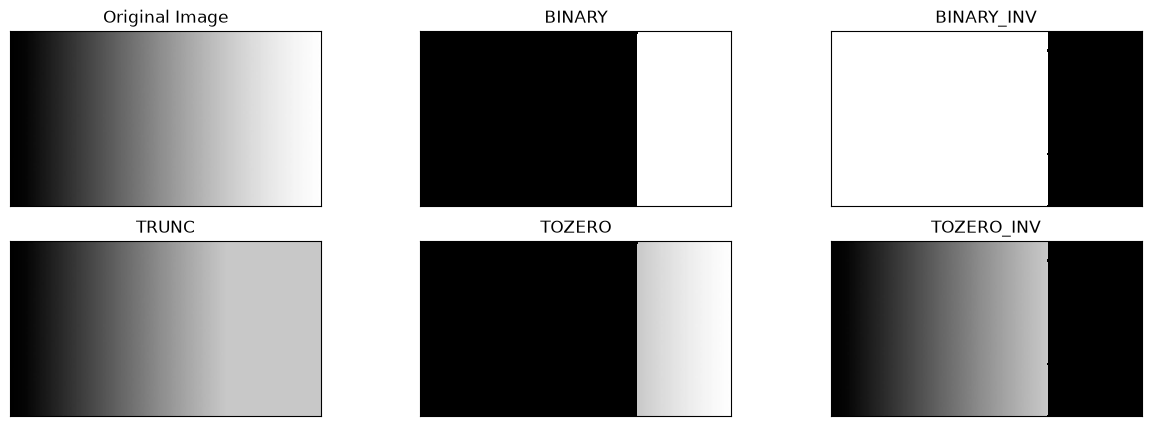

In [15]:
filename = (DIR + '/gradient.jpg')
img = cv.imread(filename)
thresh = 200 #nilai Threshold yang ditentukan
maxval=255

#1. threshold binary jika pixel di img>200, maka thresh1 bernilai 255(putih)
#selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain
#itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain
#itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu
#akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain
#itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO',
'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

## 4. Adaptive Threshold Secara Manual

Adaptive Mean dan Adaptive Gaussian **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, maupun filter siap pakai, memakai citra Sudoku yang pencahayaannya tidak merata.

Ketentuan: global threshold manual ambang 127, jendela 11 x 11, C = 2, sigma = 2 untuk Gaussian.

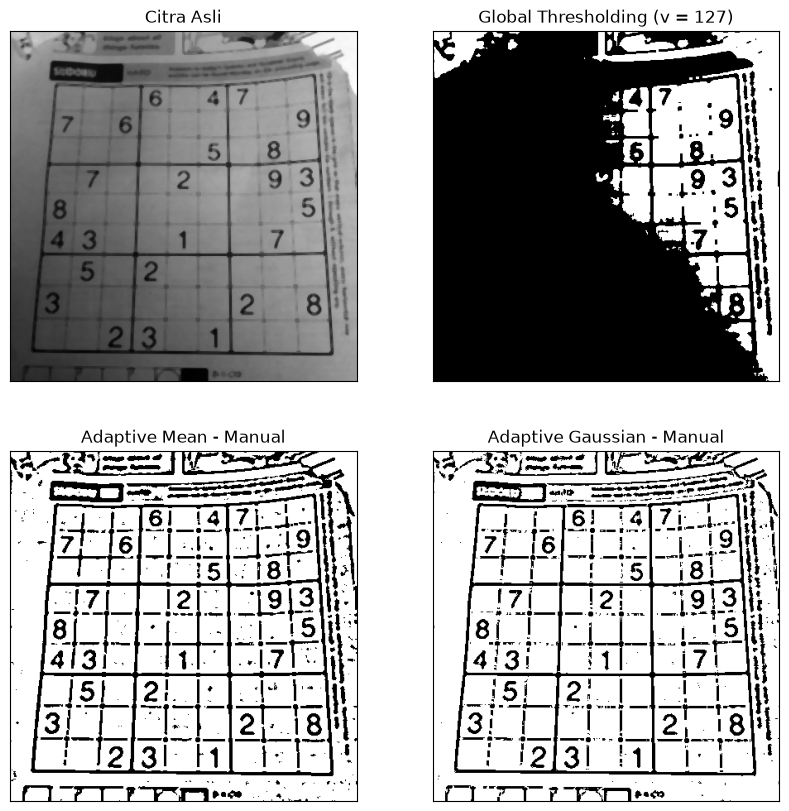

In [16]:
filename = (DIR + '/sudoku-original.jpg')
img = cv.imread(filename)

# Median blur 5x5 manual (tanpa fungsi filter siap pakai)
def median_manual(img, k=5):
  pad = k // 2
  p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
  win = np.lib.stride_tricks.sliding_window_view(p, (k, k), axis=(0, 1))
  return np.median(win, axis=(-1, -2)).astype(np.uint8)

citra = median_manual(img, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

# Global threshold manual
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

# Adaptive threshold manual (mean & gaussian)
def adaptive_manual(gray, block, C, sigma=None):
  pad = block // 2
  p = np.pad(gray.astype(np.float64), pad, mode='reflect')
  win = np.lib.stride_tricks.sliding_window_view(p, (block, block))
  if sigma is None:
    local = win.mean(axis=(-1, -2))
  else:
    ax = np.arange(block) - block // 2
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    kernel = np.outer(g, g)
    kernel /= kernel.sum()
    local = (win * kernel).sum(axis=(-1, -2))
  T = local - C
  return np.where(gray > T, 255, 0).astype(np.uint8)

th2 = adaptive_manual(gray, 11, 2)
th3 = adaptive_manual(gray, 11, 2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

## 5. Otsu Thresholding Tanpa Library

### A. Citra lena_gs_lc2.jpg
Otsu manual (tanpa `cv.threshold(..., cv.THRESH_OTSU)`), lalu dibandingkan dengan global threshold biasa.

/tmp/ipykernel_480795/1774976594.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_480795/1774976594.py:19: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


95


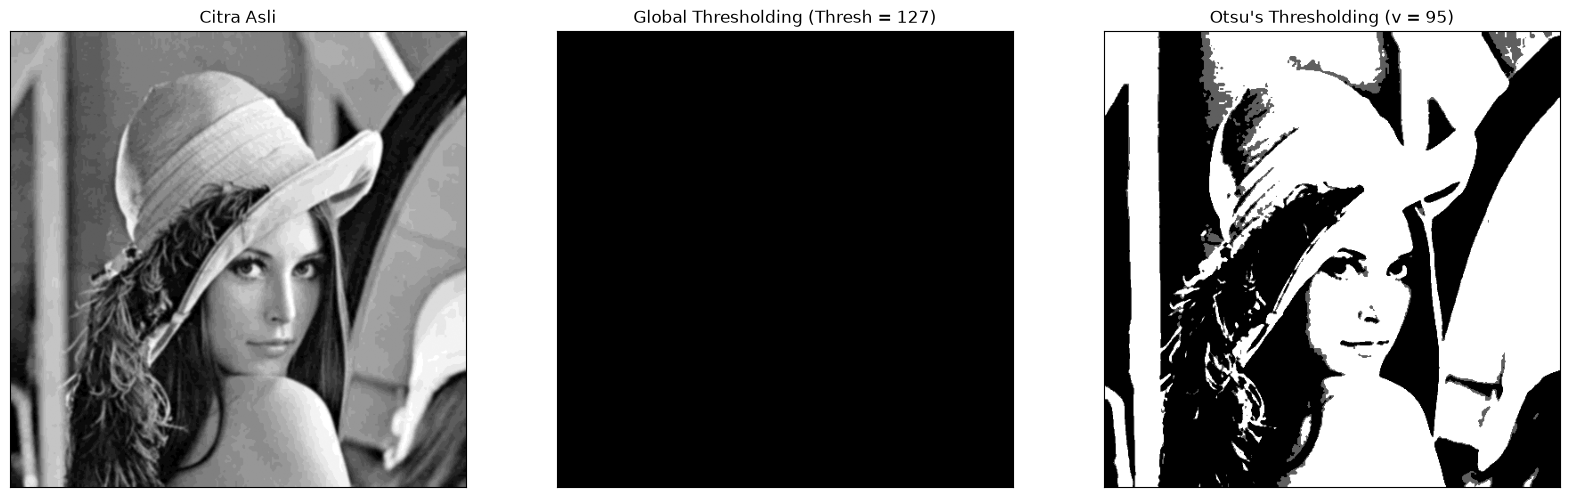

In [17]:
filename = (DIR + '/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### Pertanyaan

**Mengapa hasil Binary Thresholding semua bernilai 0 atau hitam semua?**

Karena citra `lena_gs_lc2.jpg` adalah citra low contrast dengan rentang intensitas sempit (sekitar 85-108). Nilai threshold global 127 berada **di atas** seluruh rentang intensitas citra, sehingga tidak ada piksel yang nilainya > 127. Akibatnya semua piksel menjadi 0 (hitam).

Pada histogram, seluruh distribusi piksel berada di sebelah kiri garis ambang 127.

**Berapa angka ambang batas supaya gambar Lena masih terlihat?**

Ambang harus berada di dalam rentang intensitas citra, yaitu sekitar **85-108**. Otsu memilih nilai otomatis di sekitar **95**, sehingga gambar masih terlihat. Jadi nilai global threshold yang aman adalah di sekitar 95-100, bukan 127.

### B. Citra KTP Sendiri
Membandingkan hasil Otsu manual dengan global threshold biasa pada citra KTP.

/tmp/ipykernel_480795/1774976594.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


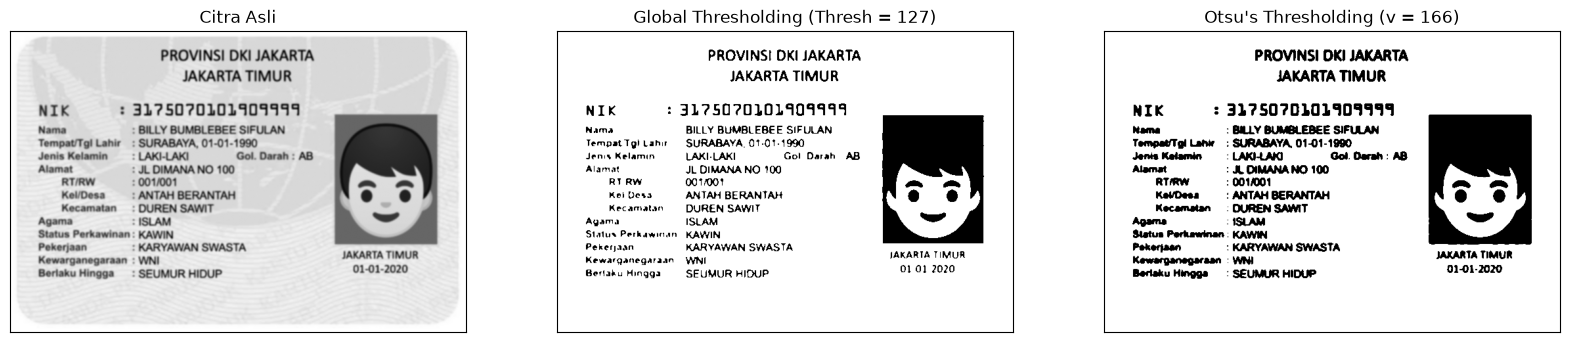

In [18]:
filename = (DIR + '/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

## 6. Segmentasi Berbasis Region

### A. Region Growing pada citra data.coins()
Menggunakan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin. Dijalankan dengan T = 5, 20, dan 60, lalu ditampilkan dalam grid (seed x T).

Seed (baris, kolom): (250, 300) | intensitas: 150.34615481468546
Seed (baris, kolom): (150, 200) | intensitas: 40.203718133645175
Seed (baris, kolom): (36, 43) | intensitas: 144.70655571875804


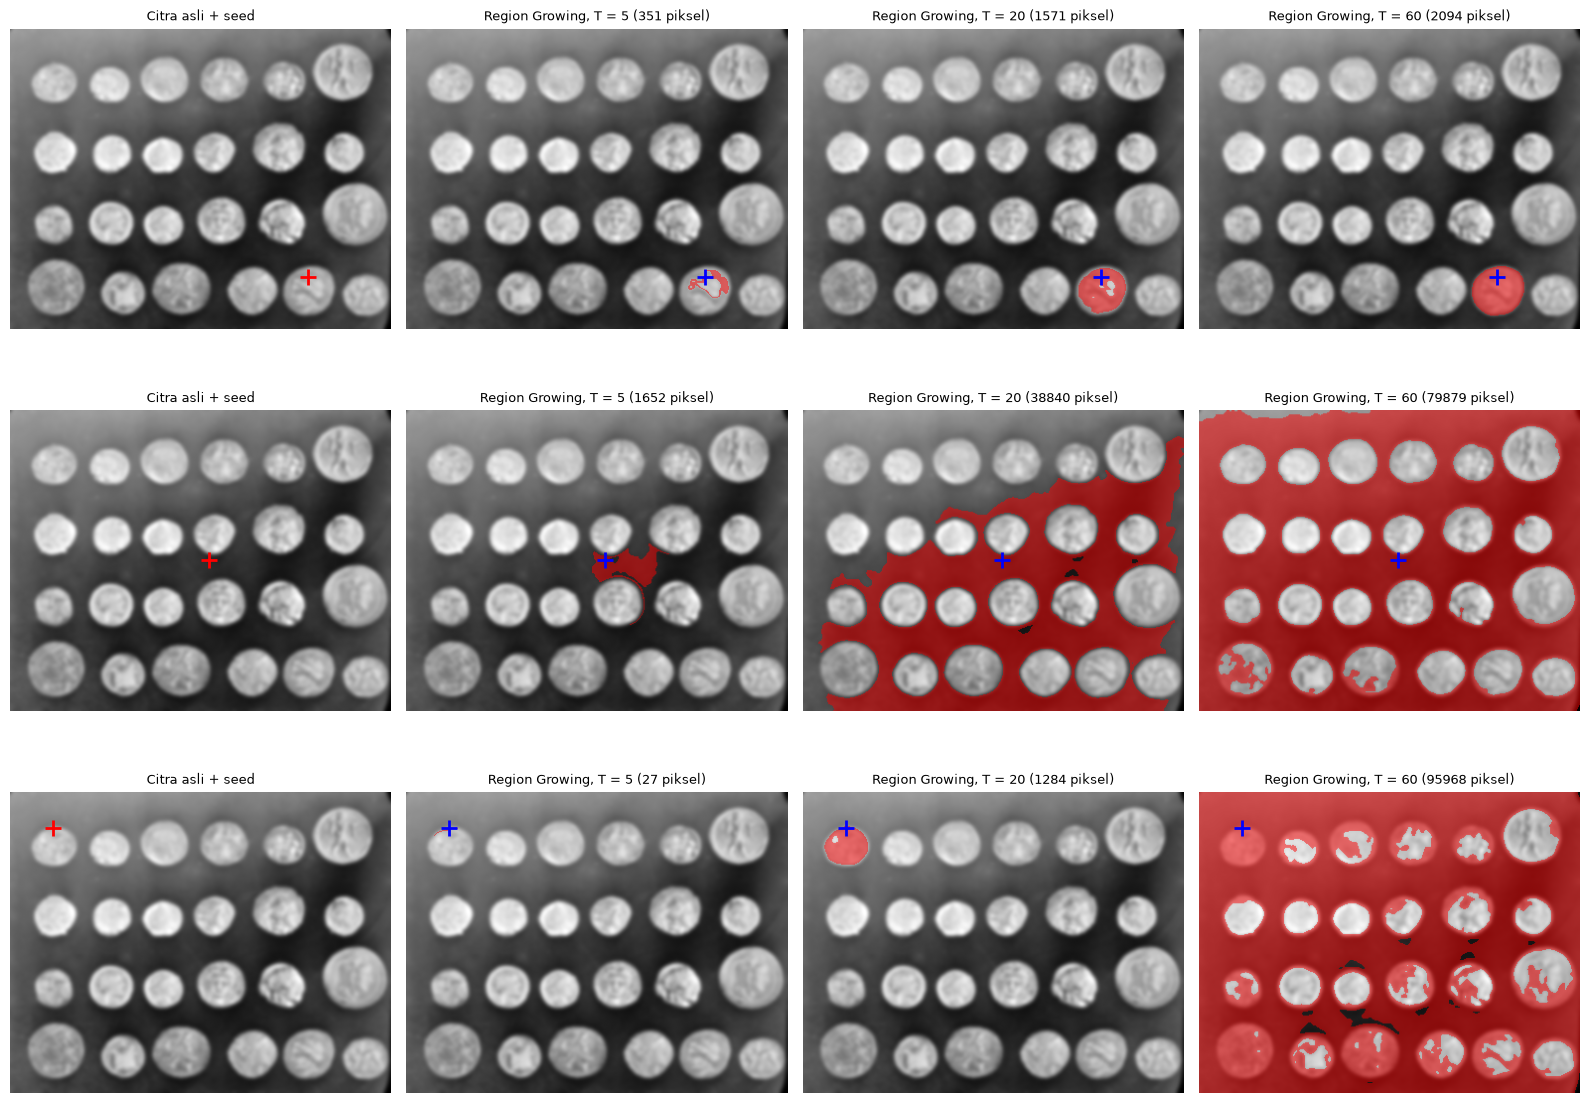

In [19]:
from skimage import data, filters

# citra coins (grayscale, 303 x 384), dihaluskan agar region lebih stabil
img_coins = filters.gaussian(data.coins().astype(float), sigma=2, preserve_range=True)

def region_growing(image, seed, T, conn=8):
    h, w = image.shape
    mask = np.zeros((h, w), bool)
    sr, sc = seed
    mask[sr, sc] = True
    total = image[sr, sc]
    count = 1
    q = deque([seed])
    if conn == 8:
        nb = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    else:
        nb = [(-1,0),(1,0),(0,-1),(0,1)]
    while q:
        r, c = q.popleft()
        ref = total / count
        for dr, dc in nb:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc]:
                if abs(image[nr, nc] - ref) < T:
                    mask[nr, nc] = True
                    total += image[nr, nc]
                    count += 1
                    q.append((nr, nc))
    return mask

seeds = {'Koin': (250, 300), 'Latar': (150, 200), 'Tepi': (36, 43)}
Ts = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, (nama, seed) in enumerate(seeds.items()):
    print('Seed (baris, kolom):', seed, '| intensitas:', img_coins[seed])
    ax = axes[i, 0]
    ax.imshow(img_coins, cmap='gray')
    ax.plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
    ax.set_title('Citra asli + seed', fontsize=9)
    ax.axis('off')
    for j, T in enumerate(Ts):
        mask = region_growing(img_coins, seed, T)
        ax = axes[i, j + 1]
        ax.imshow(img_coins, cmap='gray')
        overlay = np.zeros((*img_coins.shape, 4))
        overlay[mask] = [1, 0, 0, 0.5]
        ax.imshow(overlay)
        ax.plot(seed[1], seed[0], 'b+', markersize=12, markeredgewidth=2)
        ax.set_title(f'Region Growing, T = {T} ({mask.sum()} piksel)', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### B. Segmentasi dengan skimage.segmentation.flood()
Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

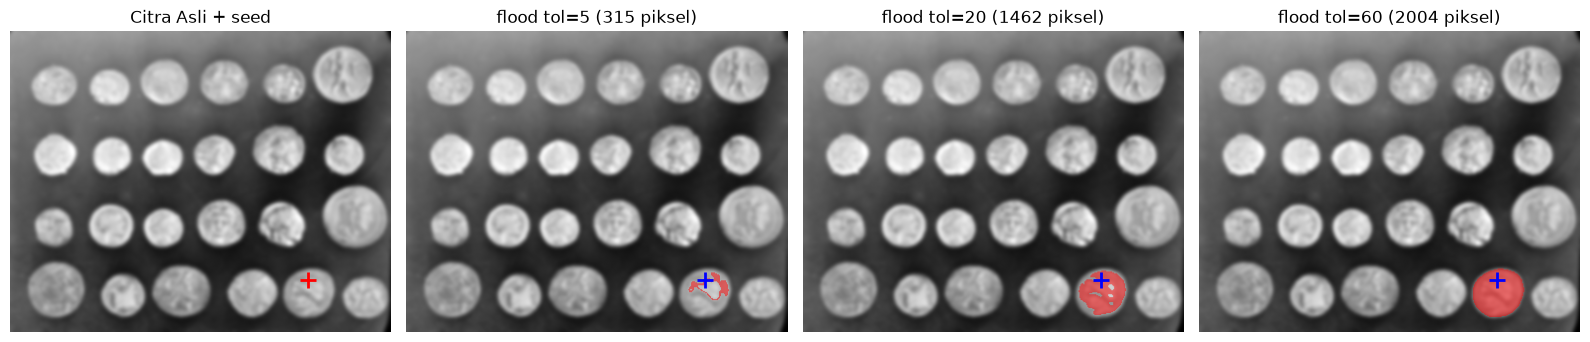

In [20]:
from skimage.segmentation import flood

seed = (250, 300)
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_coins, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
axes[0].set_title('Citra Asli + seed')
axes[0].axis('off')

for ax, tol in zip(axes[1:], tolerances):
    mask = flood(img_coins, seed, tolerance=tol)
    overlay = np.zeros((*img_coins.shape, 4))
    overlay[mask] = [1, 0, 0, 0.5]
    ax.imshow(img_coins, cmap='gray')
    ax.imshow(overlay)
    ax.plot(seed[1], seed[0], 'b+', markersize=12, markeredgewidth=2)
    ax.set_title(f'flood tol={tol} ({mask.sum()} piksel)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## D2. Tugas Kelompok — Perbandingan OCR Citra KTP

Tujuan: membandingkan kualitas pembacaan teks (OCR) **KTP setiap anggota kelompok** pada tiga citra masukan:

1. **Citra berwarna asli**
2. **Hasil segmentasi Otsu Thresholding**
3. **Hasil segmentasi Adaptive Thresholding**



In [22]:
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt

# Pengaturan OCR — sama untuk semua metode dan semua anggota kelompok
LANG = 'ind'
PSM = 6
CONF_MIN = 60


In [23]:
def normalisasi(s):
    return ' '.join(s.lower().split())

def siapkan_citra(path):
    """Menghasilkan 3 citra masukan berukuran sama: berwarna, Otsu, dan Adaptive."""
    img = cv.imread(path)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)          # grayscale untuk thresholding
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    _, otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptif = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv.THRESH_BINARY, 31, 10)
    return img, otsu, adaptif

def baca_teks(img):
    """OCR dengan bahasa dan --psm yang sama agar perbandingan konsisten."""
    citra_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    return pytesseract.image_to_string(citra_ocr, config=f'--oem 3 --psm {PSM} -l {LANG}')

def gambar_kotak(img, conf_min=CONF_MIN):
    """Citra RGB berkotak hijau pada teks ber-confidence > conf_min beserta daftar confidence."""
    citra_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    data = pytesseract.image_to_data(citra_ocr, config=f'--oem 3 --psm {PSM} -l {LANG}',
                                     output_type=Output.DICT)
    vis = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    confs = []
    for i, teks in enumerate(data['text']):
        if teks.strip() == '':
            continue
        conf = int(data['conf'][i])
        if conf >= 0:
            confs.append(conf)
        if conf > conf_min:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return cv.cvtColor(vis, cv.COLOR_BGR2RGB), confs

def cocok(item, teks):
    """Cocok bila seluruh huruf/angka item ada pada hasil OCR (abaikan besar-kecil huruf dan spasi tepi)."""
    return normalisasi(item) in normalisasi(teks)

def baris_terdekat(item, teks, cutoff=0.55):
    """Baris OCR yang paling mendekati item acuan, untuk ditampilkan pada tabel."""
    target = normalisasi(item)
    baris = [l.strip() for l in teks.splitlines() if l.strip()]
    best, best_r = '-', 0.0
    for l in baris:
        if target in normalisasi(l):
            return l
        r = difflib.SequenceMatcher(None, target, normalisasi(l)).ratio()
        if r > best_r:
            best_r, best = r, l
    return best if best_r >= cutoff else '-'


KTP Fulan | Berwarna asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahir : SURABAYA, 01-01-1990
Jenis Kelamin — : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N /

Kecamatan : DUREN SAWIT -
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JARARTA- BMA
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

KTP Fulan | Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgi Lahir : SURABAYA, 01-01-1990
Alamat : J OIMANANO 100

RTRW : 0014001

KelDesa —— : ANTAH BERANTAH .i ! ,'

Kecamatan — : DUREN SAMT
Sistus Perhawinan : KAWIN
Pekerjaan aa i W… SWASTA TA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

KTP Fulan | Segmentasi Adaptive
FII N — ——————
i PROVINSI DKI JAKARTA n
E .. JAKARTA TIMUR :
SE NIK : 3175070101999999 S
Ee Nama “ . #BILYBUMBLEBEESIFULAN 5
F:_Tempa!ngl Lahir : SURABA

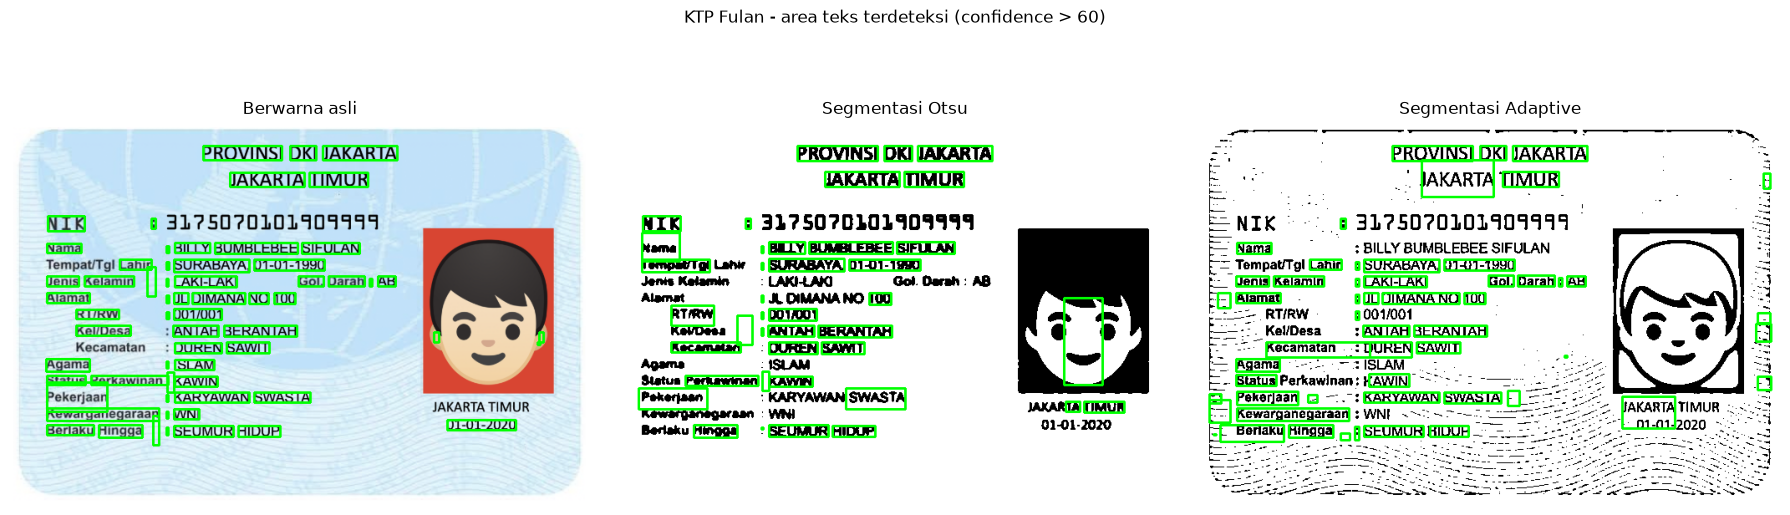


--- Tabel perbandingan KTP Fulan ---
 No.         Teks sebenarnya                           OCR Berwarna asli                        OCR Segmentasi Otsu                                          OCR Segmentasi Adaptive
   1        3175070101909999                      NIK : 3175070101909999                     NIK : 3175070101909999                                      SE NIK : 3175070101999999 S
   2 BILLY BUMBLEBEE SIFULAN              Nama : BILLY BUMBLEBEE SIFULAN             Nama : BILLY BUMBLEBEE SIFULAN                              Ee Nama “ . #BILYBUMBLEBEESIFULAN 5
   3                SURABAYA     Tempat/Tgi Lahir : SURABAYA, 01-01-1990    TempatiTgi Lahir : SURABAYA, 01-01-1990                      F:_Tempa!ngl Lahir : SURABAYA, 91-01-1990 -
   4              01-01-1990     Tempat/Tgi Lahir : SURABAYA, 01-01-1990    TempatiTgi Lahir : SURABAYA, 01-01-1990                                                                -
   5               LAKI-LAKI Jenis Kelamin — : LAKI-LAKI 

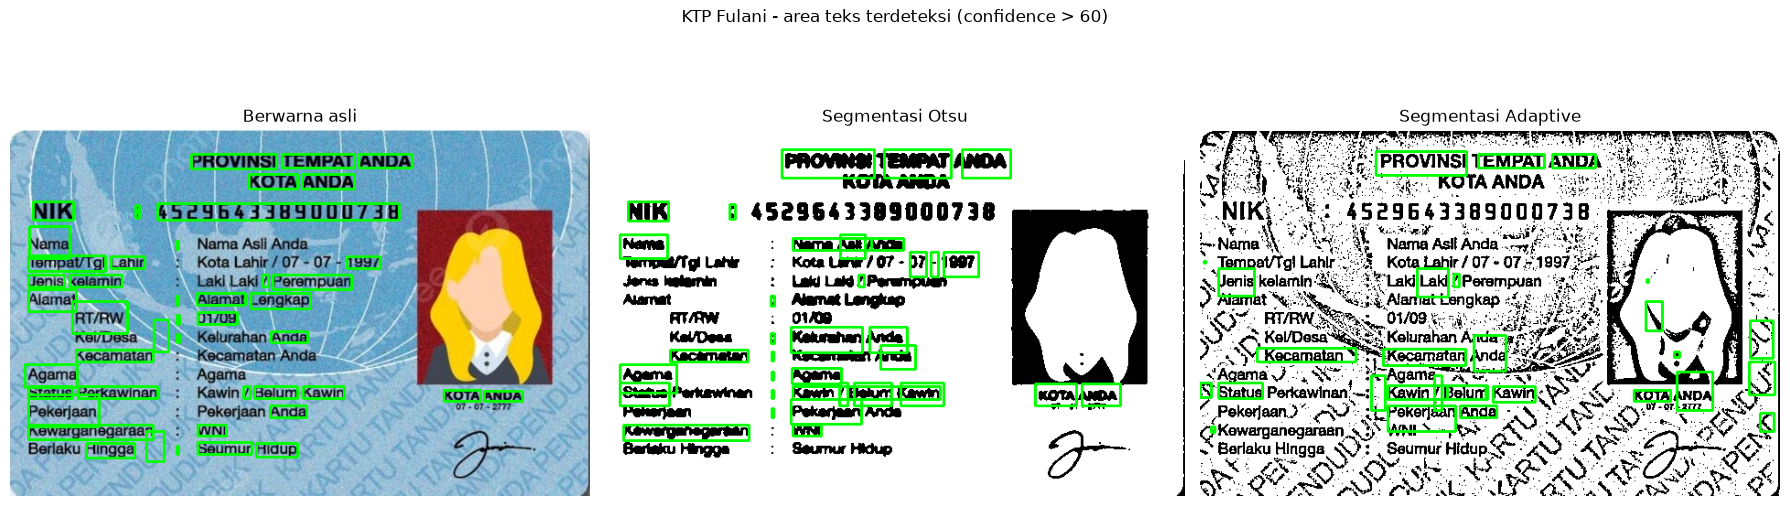


--- Tabel perbandingan KTP Fulani ---
 No.  Teks sebenarnya                                 OCR Berwarna asli                               OCR Segmentasi Otsu                                         OCR Segmentasi Adaptive
   1 4529643389000738                            NIK : 4529643389000738                            NIK : 4529643389000738                           NIK X3 4529643389000738  pemmoareng «
   2   Nama Asli Anda                               Nama : NamaAsilAnda                              Nama : Nama Asi Anda                                                               -
   3       07-07-1997                                                 -                                                 -                                                               -
   4        Laki Laki                                                 -                                                 -                                                               -
   5            01/09          

In [ ]:
# Placheolder KTP 
DAFTAR_KTP = [
    ('Fulan',  DIR + '/ktp_fulan.jpg',
     ['3175070101909999', 'BILLY BUMBLEBEE SIFULAN', 'SURABAYA', '01-01-1990',
      'LAKI-LAKI', 'ISLAM', 'KAWIN', 'KARYAWAN SWASTA', 'WNI', 'SEUMUR HIDUP']),
    ('Fulani', DIR + '/ktp_fulani.jpg',
     ['4529643389000738', 'Nama Asli Anda', '07-07-1997', 'Laki Laki', '01/09',
      'Kelurahan Anda', 'Kecamatan Anda', 'Kawin', 'WNI', 'Seumur Hidup']),
]

ringkasan = []
for nama, path, gt in DAFTAR_KTP:
    img, otsu, adaptif = siapkan_citra(path)
    metode = [('Berwarna asli', img), ('Segmentasi Otsu', otsu),
              ('Segmentasi Adaptive', adaptif)]

    hasil, conf_avg = {}, {}
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (label, im) in zip(axes, metode):
        hasil[label] = baca_teks(im)
        vis, confs = gambar_kotak(im)
        conf_avg[label] = float(np.mean(confs)) if confs else 0.0
        ax.imshow(vis)
        ax.set_title(label)
        ax.axis('off')
        print('=' * 70)
        print(f'KTP {nama} | {label}')
        print(hasil[label])
    plt.suptitle(f'KTP {nama} - area teks terdeteksi (confidence > {CONF_MIN})')
    plt.tight_layout()
    plt.show()

    # Tabel perbandingan 10 item acuan untuk anggota ini
    rows, tepat = [], {m[0]: 0 for m in metode}
    for i, item in enumerate(gt, 1):
        row = {'No.': i, 'Teks sebenarnya': item}
        for label, _ in metode:
            tepat[label] += int(cocok(item, hasil[label]))
            row[f'OCR {label}'] = baris_terdekat(item, hasil[label])
        rows.append(row)
    print(f'\n--- Tabel perbandingan KTP {nama} ---')
    print(pd.DataFrame(rows).to_string(index=False))

    # Ringkasan per anggota
    for label, _ in metode:
        ringkasan.append({
            'Anggota': nama,
            'Citra masukan OCR': label,
            'Item terbaca tepat': tepat[label],
            'Kecocokan (%)': round(100 * tepat[label] / len(gt), 1),
            'Rata-rata confidence': round(conf_avg[label], 1),
        })

print('\n================ RINGKASAN KESELURUHAN ================')
print(pd.DataFrame(ringkasan).to_string(index=False))


### Pertanyaan Analisis

1. **Citra masukan mana yang menghasilkan pembacaan paling tepat?**
  

2. **Contoh kesalahan pembacaan.**


3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?**
   

4. **Pengaruh warna/pola latar belakang.**
  

5. **Apakah confidence tertinggi selalu berarti kecocokan tertinggi?**
 
